Epoch: 1 Loss: 2.0330103782488824
Epoch: 2 Loss: 1.1777751932824656
Epoch: 3 Loss: 0.8468834078389157
Epoch: 4 Loss: 0.6890146072125635
Epoch: 5 Loss: 0.5950496095905824
Epoch: 6 Loss: 0.5315751110564231
Epoch: 7 Loss: 0.4878200487136966
Epoch: 8 Loss: 0.45637854768364566
Epoch: 9 Loss: 0.43238116657831416
Epoch: 10 Loss: 0.4130721441678727
Test Accuracy: 90.97


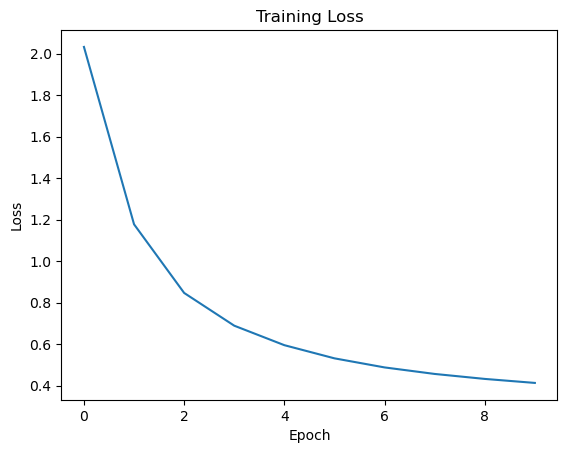

Enter test image index:  500


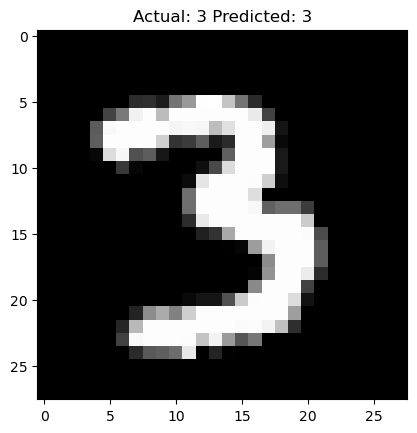

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

(X_train,y_train),(X_test,y_test)=mnist.load_data()
X_train=X_train.reshape(-1,784)/255.0
X_test=X_test.reshape(-1,784)/255.0
Y=np.eye(10)[y_train]

np.random.seed(42)
W1=np.random.randn(784,64)*0.01
b1=np.zeros((1,64))
W2=np.random.randn(64,10)*0.01
b2=np.zeros((1,10))

def sigmoid(x):
    return 1/(1+np.exp(-np.clip(x,-500,500)))

losses=[]
for epoch in range(10):
    for i in range(0,len(X_train),256):
        x=X_train[i:i+256]
        y=Y[i:i+256]
        a1=sigmoid(x@W1+b1)
        a2=sigmoid(a1@W2+b2)
        dz2=(a2-y)/len(x)
        dW2=a1.T@dz2
        db2=dz2.sum(axis=0,keepdims=True)
        dz1=(dz2@W2.T)*a1*(1-a1)
        dW1=x.T@dz1
        db1=dz1.sum(axis=0,keepdims=True)
        W2-=0.1*dW2
        b2-=0.1*db2
        W1-=0.1*dW1
        b1-=0.1*db1
    loss=-np.mean(np.sum(Y*np.log(sigmoid(sigmoid(X_train@W1+b1)@W2+b2)+1e-8),axis=1))
    losses.append(loss)
    print("Epoch:",epoch+1,"Loss:",loss)

pred=np.argmax(sigmoid(sigmoid(X_test@W1+b1)@W2+b2),axis=1)
print("Test Accuracy:",np.mean(pred==y_test)*100)

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

i=int(input("Enter test image index: "))
plt.imshow(X_test[i].reshape(28,28),cmap="gray")
plt.title("Actual: "+str(y_test[i])+" Predicted: "+str(pred[i]))
plt.show()